# Pruning outcomes in the CAFA training HOGs

Each input tree contains at least one training protein. The pruning rule removes test proteins and eligible OMA sister tips, then collapses unary nodes. HOGs with fewer than two surviving proteins are excluded. This notebook reads the completed run and its independent QC report.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set PRUNED_EXPORT_RUN to a dated export to inspect it. The default is the historical QC run.
run_name = os.environ.get("PRUNED_EXPORT_RUN", "pruned_export_4rvbve63")
roots = [Path.cwd(), *Path.cwd().parents]
candidates = [base / suffix / "results" / run_name for base in roots
              for suffix in ("", "HOGprop_validation_project/analysis/02_fastoma_output_processing")]
run = next(path for path in candidates if (path / "hog_manifest.tsv").is_file())
hogs = pd.read_csv(run / "hog_manifest.tsv", sep="\t")
kept = hogs.new_hog_id.notna()
qc = json.loads((run / "external_qc.json").read_text())
print(pd.Series(qc).to_string())

verified_test_removals      92061
verified_oma_removals       67731
verified_hog_folders        29137
verified_proteins         8397020
excluded_hogs                 523
verified_xml_roots          29137


## HOG retention and protein fates

Counts use different units. A protein that survives pruning can still be excluded when its HOG becomes a singleton.

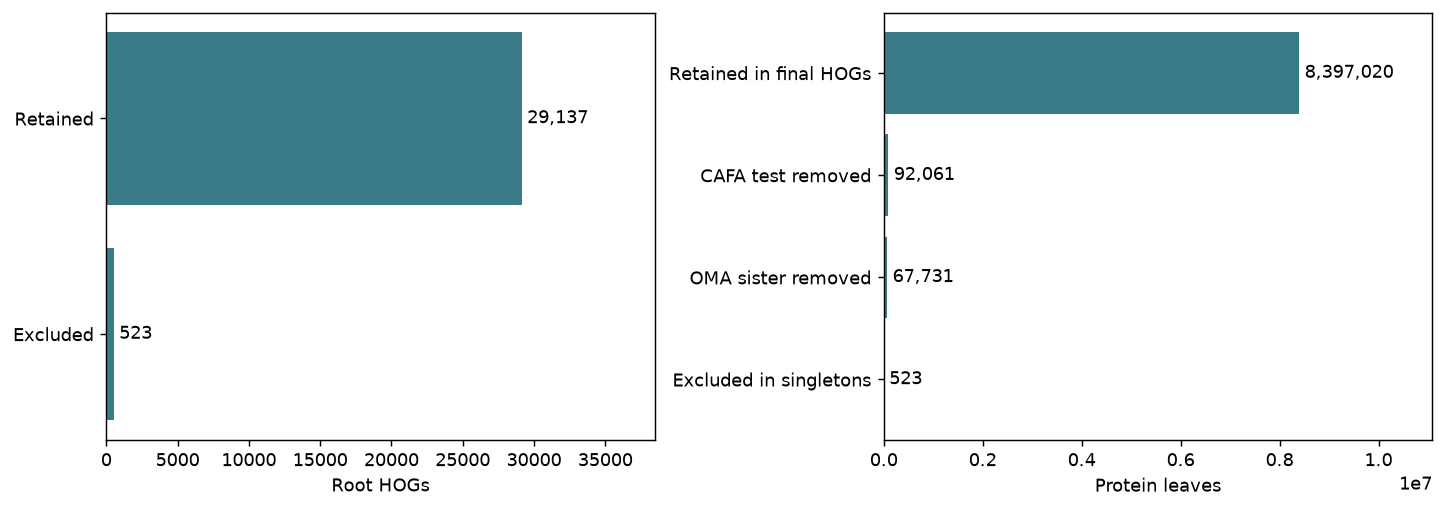

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
panels = [
    (axes[0], ["Retained", "Excluded"], [kept.sum(), (~kept).sum()], "Root HOGs"),
    (axes[1], ["Retained in final HOGs", "CAFA test removed", "OMA sister removed", "Excluded in singletons"],
     [hogs.loc[kept,"remaining_proteins"].sum(), hogs.removed_test.sum(), hogs.removed_oma.sum(),
      hogs.loc[~kept,"remaining_proteins"].sum()], "Protein leaves"),
]
for ax, labels, counts, unit in panels:
    bars = ax.barh(labels, counts, color="#397b88")
    ax.bar_label(bars, labels=[f"{x:,}" for x in counts], padding=3)
    ax.set_xlim(0, max(counts)*1.32)
    ax.invert_yaxis()
    ax.set_xlabel(unit)
plt.show()

## Tree sizes and unary-node collapse

The diagonal marks trees with equal tip counts before and after pruning. The histogram includes every input HOG.

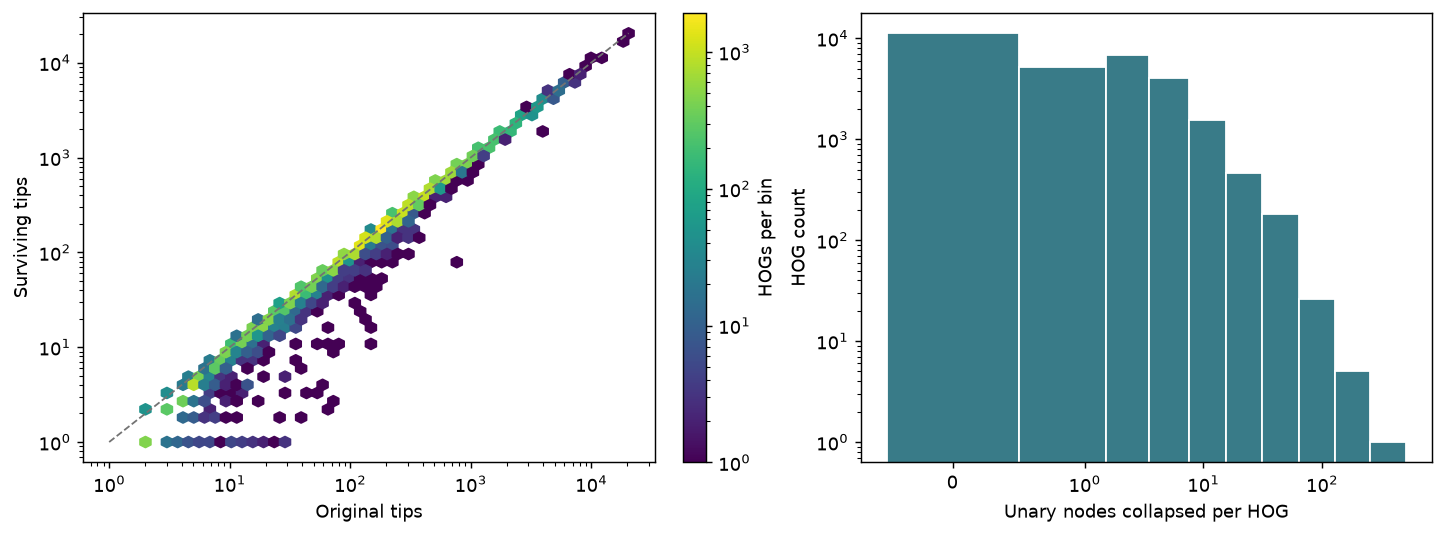

In [3]:
fig, (ax, hist) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
points = ax.hexbin(hogs.original_tips, hogs.remaining_proteins, xscale="log", yscale="log",
                   gridsize=45, bins="log", mincnt=1, cmap="viridis")
limit = hogs.original_tips.max()
ax.plot([1,limit],[1,limit], color="0.45", ls="--", lw=1)
ax.set(xlabel="Original tips", ylabel="Surviving tips")
fig.colorbar(points, ax=ax, label="HOGs per bin")
bins = np.r_[-0.5, 0.5, 2**np.arange(1, np.ceil(np.log2(hogs.collapsed.max()+1))+1)-0.5]
hist.hist(hogs.collapsed, bins=bins, color="#397b88", edgecolor="white")
hist.set_xscale("symlog", linthresh=1)
hist.set_yscale("log")
hist.set(xlabel="Unary nodes collapsed per HOG", ylabel="HOG count")
plt.show()

## Which training proteins had an eligible OMA sister?

The ten taxa with the most training proteins are shown. Each denominator includes all training proteins assigned to input HOGs for that taxon. The assignment table comes from the earlier independent audit of the same cohort.

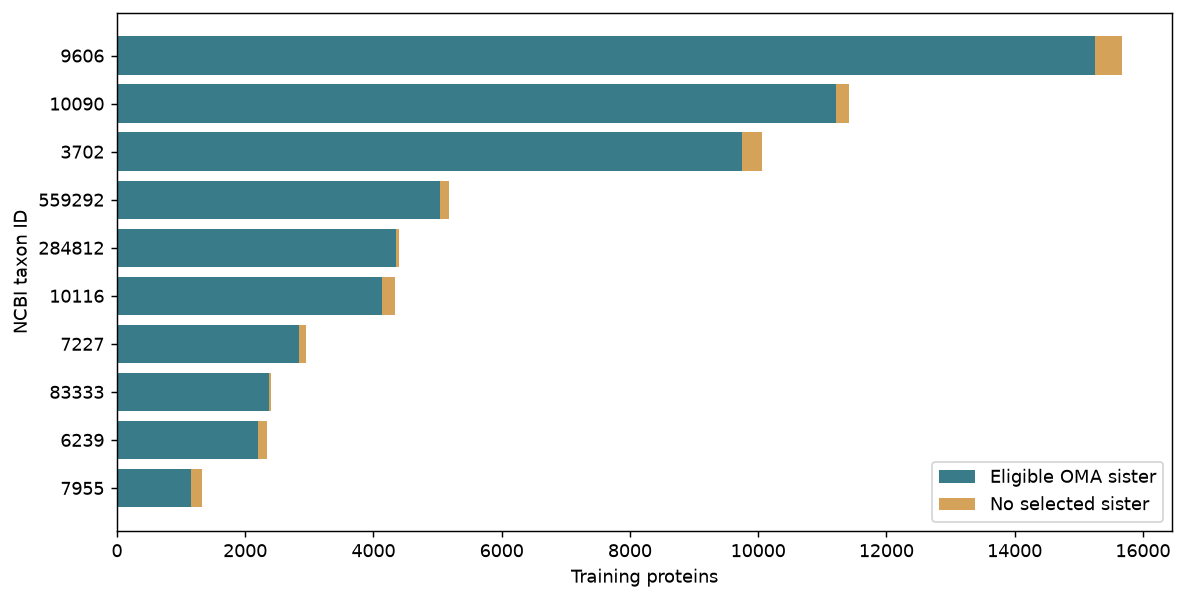

In [4]:
audit_dir = run.parent / "sister_nhx_stage01_59a3327e8ca1"
pairs = pd.read_csv(audit_dir / "pruning_assignments.tsv", sep="\t", dtype={"taxon": str})
by_taxon = (pairs.assign(matched=pairs.selected_oma_gene_id.notna())
            .groupby("taxon").matched.agg(["sum", "size"]).nlargest(10, "size").iloc[::-1])
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.barh(by_taxon.index, by_taxon["sum"], label="Eligible OMA sister", color="#397b88")
ax.barh(by_taxon.index, by_taxon["size"] - by_taxon["sum"], left=by_taxon["sum"],
        label="No selected sister", color="#d5a259")
ax.set(xlabel="Training proteins", ylabel="NCBI taxon ID")
ax.legend()
plt.show()

## Example HOG before and after pruning

This is the HOG used to develop the filtering rule. Tip labels show XML gene ID and species. Internal labels distinguish speciation-like (S) and duplication-like (D) events. The two panels align surviving proteins on the same rows.

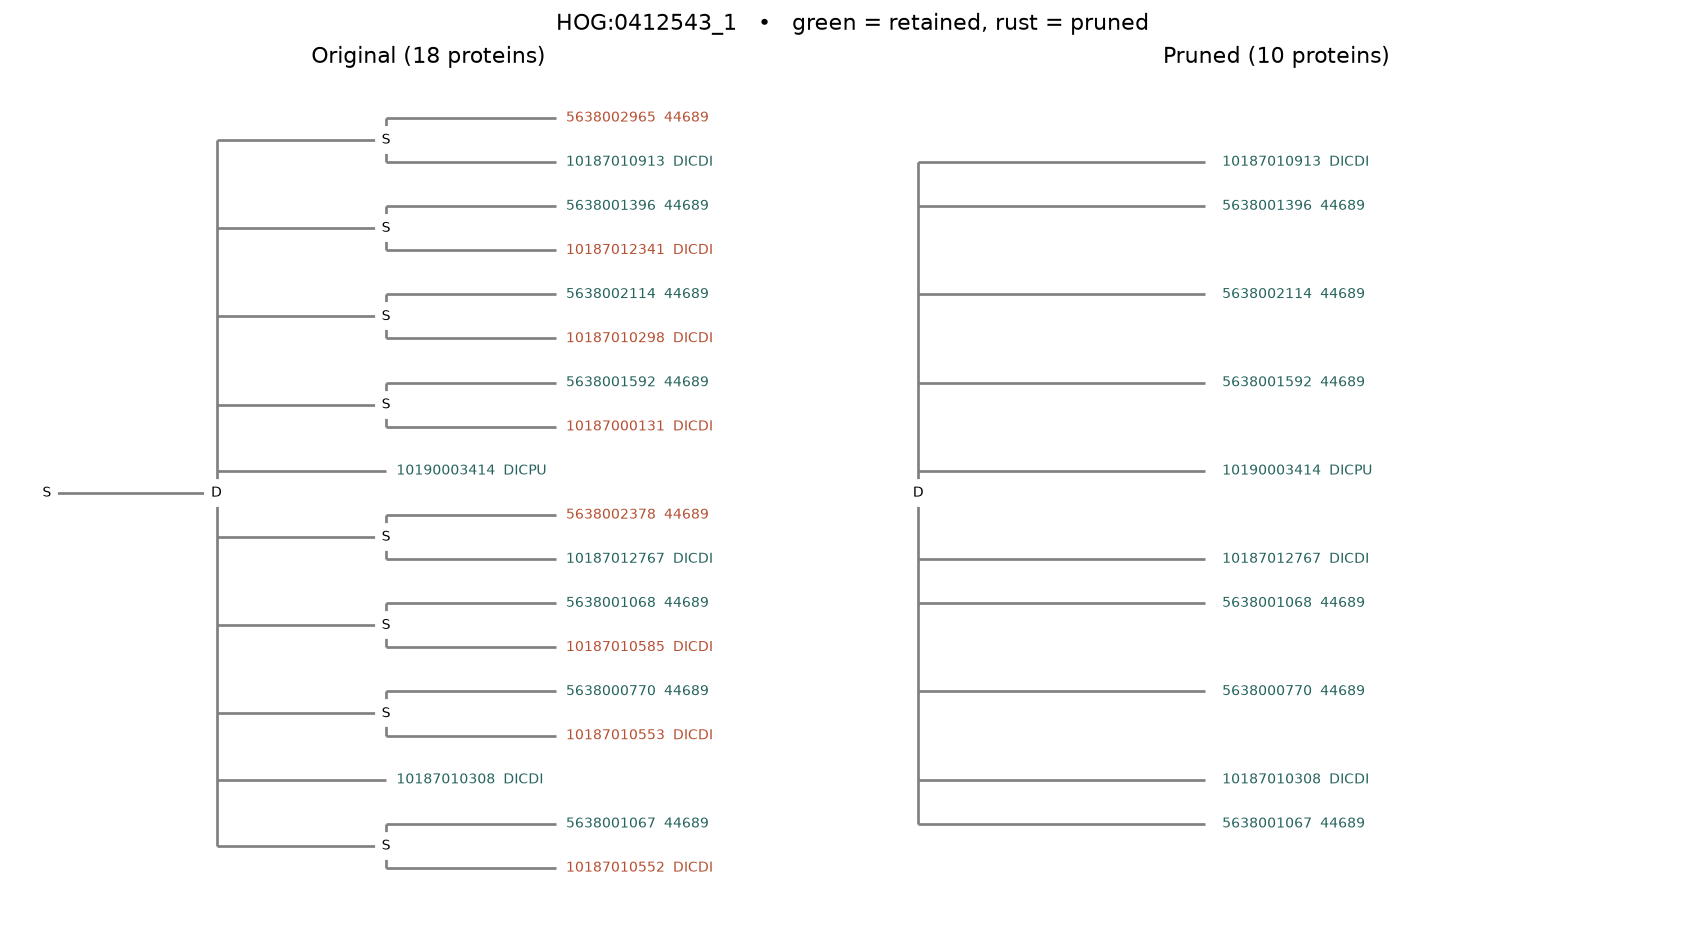

In [5]:
from ete4 import Tree
example = hogs.loc[hogs.original_hog_id == "HOG:0412543_1"].iloc[0]
reference = run.parent / "sister_nhx_stage01_59a3327e8ca1" / "unpruned"
original = Tree((reference / f"tree_{example.original_hog_id}.nwk").read_text(), parser=1)
final = Tree((run / "hogs" / example.folder / "pruned.nhx").read_text(), parser=1)
retained = {leaf.name for leaf in final.leaves()}
rows = {leaf.name: i for i, leaf in enumerate(reversed(list(original.leaves())))}
fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout="constrained")
for ax, tree, label in zip(axes, (original, final), ("Original", "Pruned")):
    x = {tree: 0}
    y = {}
    for node in tree.traverse("preorder"):
        for child in node.children:
            x[child] = x[node] + 1
    for node in tree.traverse("postorder"):
        if node.is_leaf:
            y[node] = rows[node.name]
            color = "#25635c" if node.name in retained else "#b54f32"
            ax.text(x[node]+0.06, y[node], f"{node.name}  {node.props['S']}", va="center", color=color, fontsize=8)
        else:
            positions = [y[c] for c in node.children]
            y[node] = (min(positions)+max(positions))/2
            ax.vlines(x[node], min(positions), max(positions), color="0.5")
            for c in node.children:
                ax.hlines(y[c], x[node], x[c], color="0.5")
            event = {"0>1":"S","1>0":"D"}.get(node.props.get("Ev"), "?")
            ax.text(x[node], y[node], event, ha="center", va="center", backgroundcolor="white", fontsize=8)
    ax.set(xlim=(-0.2, max(x.values())+1.7), ylim=(-1,len(rows)))
    ax.set_title(f"{label} ({len(tree)} proteins)")
    ax.set_axis_off()
fig.suptitle(f"{example.original_hog_id}   •   green = retained, rust = pruned")
plt.show()

## OrthoXML reader and taxonomy checks

HOGPROP’s reader loaded all 29,137 roots and 8,397,020 gene references. All root HOG IDs are unique. Irene’s converter repeats group IDs within 27,131 HOGs, so an internal ID alone cannot identify a particular node. The XML contains 177 outer orthologGroup wrappers for duplication roots. The saved NHX trees contain zero unary nodes.

The export retains 4,087 original species records and the original 15,683 taxonomy nodes. The source species records carry NCBITaxId zero. Per-leaf species comparisons use the mapped taxon in members.tsv. This run checked the reader and the pruning results. GO propagation and branch-length estimation are separate stages.
